Gradient Descent (lr = 0.01)   final loss = 1.0350, test accuracy = 0.4917
Adam (lr = 0.01)               final loss = 0.2991, test accuracy = 0.7833

Epoch   GD loss   Adam loss
    1    1.2905     1.2905
   10    1.2568     0.9152
   25    1.2073     0.5999
   50    1.1384     0.3503
   75    1.0821     0.3097
  100    1.0350     0.2991
Gradient Descent (lr = 0.01)   epochs to reach loss < 0.4:  not reached in 100 epochs | std of epoch-to-epoch change (last 50): 0.00021
Adam (lr = 0.01)               epochs to reach loss < 0.4:  42 | std of epoch-to-epoch change (last 50): 0.00082


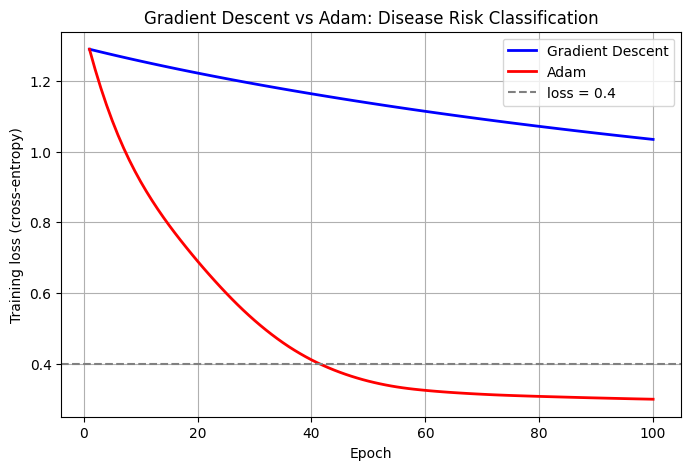

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

np.random.seed(4)

# Step 1: Patient records (6 features) -> risk class: 0 = low, 1 = medium, 2 = high
n = 600
X = np.random.normal(0, 1, (n, 6))
W_true = np.random.normal(0, 1, (6, 3))
logits = X @ W_true + np.random.normal(0, 0.5, (n, 3))
y = np.argmax(logits, axis=1)
X_train, y_train = X[:480], y[:480]
X_test, y_test = X[480:], y[480:]

# Step 2: Same network, same initial weights, same batch size and epochs
def build_model():
    tf.keras.utils.set_random_seed(4)
    return keras.Sequential([
        keras.layers.Input(shape=(6,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(3, activation="softmax")])

optimizers = {
    "Gradient Descent (lr = 0.01)": keras.optimizers.SGD(learning_rate=0.01),
    "Adam (lr = 0.01)": keras.optimizers.Adam(learning_rate=0.01),
}
epochs = 100
losses = {}

for name, opt in optimizers.items():
    model = build_model()
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    # full batch -> one weight update per epoch (ordinary gradient descent)
    h = model.fit(X_train, y_train, epochs=epochs, batch_size=len(X_train), verbose=0)
    losses[name] = np.array(h.history["loss"])
    test_acc = model.evaluate(X_test, y_test, verbose=0)[1]
    print(f"{name:30s} final loss = {losses[name][-1]:.4f}, test accuracy = {test_acc:.4f}")

# Step 3: Convergence speed and stability
gd, adam = losses["Gradient Descent (lr = 0.01)"], losses["Adam (lr = 0.01)"]
print("\nEpoch   GD loss   Adam loss")
for e in [1, 10, 25, 50, 75, 100]:
    print(f"{e:5d}   {gd[e-1]:7.4f}   {adam[e-1]:8.4f}")
target = 0.40
for name, v in losses.items():
    r = np.where(v < target)[0]
    print(f"{name:30s} epochs to reach loss < {target}: ",
          int(r[0]) + 1 if len(r) else "not reached in 100 epochs",
          "| std of epoch-to-epoch change (last 50):",
          round(float(np.std(np.diff(v[-50:]))), 5))

# Step 4: Plot the loss curves
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), gd, "b-", linewidth=2, label="Gradient Descent")
plt.plot(range(1, epochs + 1), adam, "r-", linewidth=2, label="Adam")
plt.axhline(target, color="gray", linestyle="--", label=f"loss = {target}")
plt.xlabel("Epoch")
plt.ylabel("Training loss (cross-entropy)")
plt.title("Gradient Descent vs Adam: Disease Risk Classification")
plt.legend()
plt.grid(True)
plt.show()